In [1]:
import pandas as pd
import sqlite3 as sq
import matplotlib as mpl
from matplotlib import rcParams
import matplotlib.pyplot as plt
import numpy as np
import geopandas as gpd
import fiona
import os
import io
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.functions import read_census_table, read_wp23_table

In [2]:
tnurbansim = gpd.read_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\2-outputs\2-geospatial\BaseYear.gpkg", layer="TN_All")
tngnrc = gpd.read_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\2-outputs\2-geospatial\BaseYear.gpkg", layer="TN_EMP_2")

In [3]:
tn = tnurbansim.drop(columns = ['geometry', 'COUNTYFP', 'HHPOP']).set_index(['GEO_ID', 'COUNTY']).add_suffix('_US').reset_index(drop = False)
tn_2 = tngnrc.drop(columns = ['COUNTYFP']).set_index(['GEO_ID', 'COUNTY', 'geometry']).add_suffix('_GNRC').reset_index(drop = False)

In [4]:
tn_joined = tn.merge(tn_2, on = ['GEO_ID', 'COUNTY'])
tn_geo = gpd.GeoDataFrame(data = tn_joined, geometry = tn_joined.geometry, crs = tngnrc.crs)

In [5]:
tn_geo.head(2)

,GEO_ID,COUNTY,EMP_US,EMP_OTHER_US,EMP_SERVICE_US,EMP_RETAIL_US,EMP_OFFICE_US,EMP_MEDICAL_US,EMP_INDUSTRIAL_US,EMP_GOVERNMENT_US,...,EMP_GNRC,EMP_EDUCATION_GNRC,EMP_FOODSERVICE_GNRC,EMP_GOVERNMENT_GNRC,EMP_INDUSTRIAL_GNRC,EMP_MEDICAL_GNRC,EMP_OFFICE_GNRC,EMP_OTHER_GNRC,EMP_RETAIL_GNRC,EMP_SERVICE_GNRC
0,471251008001027,"Montgomery County, Tennessee",1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,5,0,0,0,0,0,0,0,5,0
1,471251008001026,"Montgomery County, Tennessee",20.0,0.0,0.0,20.0,0.0,0.0,0.0,0.0,...,17,0,0,0,0,0,0,0,17,0


In [6]:
emp_cols = ['EMP', 'EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT', 'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE', 'EMP_OTHER', 'EMP_RETAIL', 'EMP_SERVICE']

In [7]:
emp_cols = ['EMP', 'EMP_EDUCATION', 'EMP_FOODSERVICE', 'EMP_GOVERNMENT', 'EMP_INDUSTRIAL', 'EMP_MEDICAL', 'EMP_OFFICE', 'EMP_OTHER', 'EMP_RETAIL', 'EMP_SERVICE']
for col in emp_cols:
    tn_geo[f'{col}_RD'] = tn_geo[f'{col}_US'] - tn_geo[f'{col}_GNRC']
    tn_geo[f'{col}_PD'] = abs((tn_geo[f'{col}_US'] - tn_geo[f'{col}_GNRC'])/tn_geo[f'{col}_GNRC'])

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

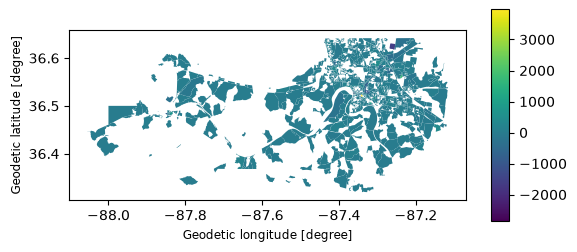

In [8]:
tn_geo.plot(column = 'EMP_RD', cmap="viridis", legend=True, vmin=tn_geo['EMP_RD'].min(), vmax=tn_geo['EMP_RD'].max(),)

In [9]:
counties = gpd.read_file("https://www2.census.gov/geo/tiger/TIGER2024/COUNTY/tl_2024_us_county.zip")

In [10]:
tn_counties_proj = counties.loc[counties['STATEFP'] == '47'].to_crs(epsg=2274)
tn_geo_proj = tn_geo.to_crs(epsg=2274)

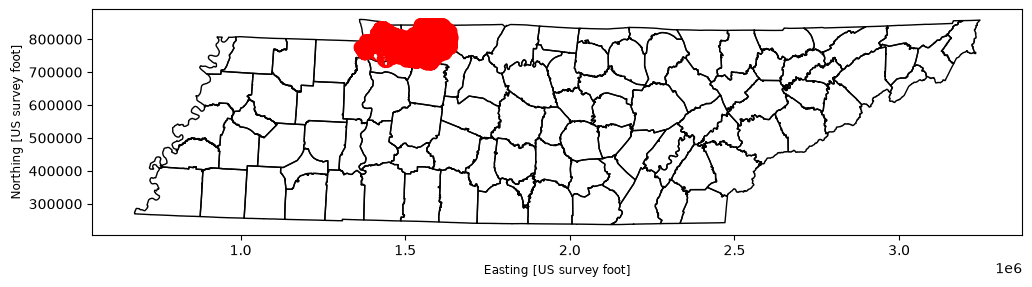

In [11]:
#plot all together just to make sure it's lookin' right
fig, ax = plt.subplots(figsize=(12, 12))

tn_counties_proj.plot(ax=ax,facecolor='none',edgecolor='black',linewidth=1)

tn_geo_proj.plot(ax=ax,facecolor='red',edgecolor='red',linewidth=10)

plt.show()

In [12]:
tn_geo_proj['EMP_RD'].describe()

count     933.000000
mean       -4.740622
std       229.898287
min     -2852.000000
25%       -15.000000
50%        -3.000000
75%        12.000000
max      3977.000000
Name: EMP_RD, dtype: float64

In [13]:
tn_geo_proj[['COUNTY', 'EMP_US', 'EMP_GNRC', 'EMP_RD', 'EMP_PD']].sort_values(by = 'EMP_RD', ascending = False).head()

,COUNTY,EMP_US,EMP_GNRC,EMP_RD,EMP_PD
220,"Montgomery County, Tennessee",4472.0,495,3977.0,8.034343
114,"Montgomery County, Tennessee",3159.0,1394,1765.0,1.266141
229,"Montgomery County, Tennessee",1491.0,423,1068.0,2.524823
668,"Montgomery County, Tennessee",907.0,147,760.0,5.170068
543,"Stewart County, Tennessee",783.0,62,721.0,11.629032


In [14]:
tn_geo_proj.to_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\1-data\2-interim\baseyear_evaluation.gpkg", layer = 'tnemp_comp')

In [15]:
tn_geo_proj.columns

Index(['GEO_ID', 'COUNTY', 'EMP_US', 'EMP_OTHER_US', 'EMP_SERVICE_US',
       'EMP_RETAIL_US', 'EMP_OFFICE_US', 'EMP_MEDICAL_US', 'EMP_INDUSTRIAL_US',
       'EMP_GOVERNMENT_US', 'EMP_FOODSERVICE_US', 'EMP_EDUCATION_US',
       'geometry', 'EMP_GNRC', 'EMP_EDUCATION_GNRC', 'EMP_FOODSERVICE_GNRC',
       'EMP_GOVERNMENT_GNRC', 'EMP_INDUSTRIAL_GNRC', 'EMP_MEDICAL_GNRC',
       'EMP_OFFICE_GNRC', 'EMP_OTHER_GNRC', 'EMP_RETAIL_GNRC',
       'EMP_SERVICE_GNRC', 'EMP_RD', 'EMP_PD', 'EMP_EDUCATION_RD',
       'EMP_EDUCATION_PD', 'EMP_FOODSERVICE_RD', 'EMP_FOODSERVICE_PD',
       'EMP_GOVERNMENT_RD', 'EMP_GOVERNMENT_PD', 'EMP_INDUSTRIAL_RD',
       'EMP_INDUSTRIAL_PD', 'EMP_MEDICAL_RD', 'EMP_MEDICAL_PD',
       'EMP_OFFICE_RD', 'EMP_OFFICE_PD', 'EMP_OTHER_RD', 'EMP_OTHER_PD',
       'EMP_RETAIL_RD', 'EMP_RETAIL_PD', 'EMP_SERVICE_RD', 'EMP_SERVICE_PD'],
      dtype='str')

In [16]:
kygnrc = gpd.read_file(r"G:\3-GitHub\FCLUCS_Scenario_Planning\2-outputs\2-geospatial\BaseYear.gpkg", layer="KY_EMP")

In [17]:
tn_ky_joined = pd.concat([kygnrc, tn])

In [18]:
tn.head()

,GEO_ID,COUNTY,EMP_US,EMP_OTHER_US,EMP_SERVICE_US,EMP_RETAIL_US,EMP_OFFICE_US,EMP_MEDICAL_US,EMP_INDUSTRIAL_US,EMP_GOVERNMENT_US,EMP_FOODSERVICE_US,EMP_EDUCATION_US
0,471251020054021,"Montgomery County, Tennessee",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,471251018072010,"Montgomery County, Tennessee",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,471251008001034,"Montgomery County, Tennessee",6.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,5.0,0.0
3,471251008001018,"Montgomery County, Tennessee",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,471251008001033,"Montgomery County, Tennessee",3.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2.0,0.0


In [19]:
tn_ky_joined.head()

,EMP,EMP_EDUCATION,EMP_FOODSERVICE,EMP_GOVERNMENT,EMP_INDUSTRIAL,EMP_MEDICAL,EMP_OFFICE,EMP_OTHER,EMP_RETAIL,EMP_SERVICE,...,EMP_US,EMP_OTHER_US,EMP_SERVICE_US,EMP_RETAIL_US,EMP_OFFICE_US,EMP_MEDICAL_US,EMP_INDUSTRIAL_US,EMP_GOVERNMENT_US,EMP_FOODSERVICE_US,EMP_EDUCATION_US
0,43.0,0.0,43.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7.0,0.0,0.0,0.0,4.0,3.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,167.0,0.0,0.0,0.0,0.0,0.0,0.0,167.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,43.0,0.0,0.0,0.0,0.0,0.0,0.0,43.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
